In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import plotly.express as px
import plotly.graph_objects as go
from scipy.stats import gaussian_kde

In [2]:
df=pd.read_csv("Zomato.csv")

In [3]:
df.head()

,url,address,name,online_order,book_table,rate,votes,phone,location,rest_type,dish_liked,cuisines,approx_cost(for two people),reviews_list,menu_item,listed_in(type),listed_in(city)
0,https://www.zomato.com/bangalore/jalsa-banasha...,"942, 21st Main Road, 2nd Stage, Banashankari, ...",Jalsa,Yes,Yes,4.1/5,775,080 42297555\r\n+91 9743772233,Banashankari,Casual Dining,"Pasta, Lunch Buffet, Masala Papad, Paneer Laja...","North Indian, Mughlai, Chinese",800,"[('Rated 4.0', 'RATED\n A beautiful place to ...",[],Buffet,Banashankari
1,https://www.zomato.com/bangalore/spice-elephan...,"2nd Floor, 80 Feet Road, Near Big Bazaar, 6th ...",Spice Elephant,Yes,No,4.1/5,787,080 41714161,Banashankari,Casual Dining,"Momos, Lunch Buffet, Chocolate Nirvana, Thai G...","Chinese, North Indian, Thai",800,"[('Rated 4.0', 'RATED\n Had been here for din...",[],Buffet,Banashankari
2,https://www.zomato.com/SanchurroBangalore?cont...,"1112, Next to KIMS Medical College, 17th Cross...",San Churro Cafe,Yes,No,3.8/5,918,+91 9663487993,Banashankari,"Cafe, Casual Dining","Churros, Cannelloni, Minestrone Soup, Hot Choc...","Cafe, Mexican, Italian",800,"[('Rated 3.0', ""RATED\n Ambience is not that ...",[],Buffet,Banashankari
3,https://www.zomato.com/bangalore/addhuri-udupi...,"1st Floor, Annakuteera, 3rd Stage, Banashankar...",Addhuri Udupi Bhojana,No,No,3.7/5,88,+91 9620009302,Banashankari,Quick Bites,Masala Dosa,"South Indian, North Indian",300,"[('Rated 4.0', ""RATED\n Great food and proper...",[],Buffet,Banashankari
4,https://www.zomato.com/bangalore/grand-village...,"10, 3rd Floor, Lakshmi Associates, Gandhi Baza...",Grand Village,No,No,3.8/5,166,+91 8026612447\r\n+91 9901210005,Basavanagudi,Casual Dining,"Panipuri, Gol Gappe","North Indian, Rajasthani",600,"[('Rated 4.0', 'RATED\n Very good restaurant ...",[],Buffet,Banashankari


In [4]:
df.tail()

,url,address,name,online_order,book_table,rate,votes,phone,location,rest_type,dish_liked,cuisines,approx_cost(for two people),reviews_list,menu_item,listed_in(type),listed_in(city)
51712,https://www.zomato.com/bangalore/best-brews-fo...,"Four Points by Sheraton Bengaluru, 43/3, White...",Best Brews - Four Points by Sheraton Bengaluru...,No,No,3.6 /5,27,080 40301477,Whitefield,Bar,NaN,Continental,"1,500","[('Rated 5.0', ""RATED\n Food and service are ...",[],Pubs and bars,Whitefield
51713,https://www.zomato.com/bangalore/vinod-bar-and...,"Number 10, Garudachar Palya, Mahadevapura, Whi...",Vinod Bar And Restaurant,No,No,NaN,0,+91 8197675843,Whitefield,Bar,NaN,Finger Food,600,[],[],Pubs and bars,Whitefield
51714,https://www.zomato.com/bangalore/plunge-sherat...,Sheraton Grand Bengaluru Whitefield Hotel & Co...,Plunge - Sheraton Grand Bengaluru Whitefield H...,No,No,NaN,0,NaN,Whitefield,Bar,NaN,Finger Food,"2,000",[],[],Pubs and bars,Whitefield
51715,https://www.zomato.com/bangalore/chime-sherato...,Sheraton Grand Bengaluru Whitefield Hotel & Co...,Chime - Sheraton Grand Bengaluru Whitefield Ho...,No,Yes,4.3 /5,236,080 49652769,"ITPL Main Road, Whitefield",Bar,"Cocktails, Pizza, Buttermilk",Finger Food,"2,500","[('Rated 4.0', 'RATED\n Nice and friendly pla...",[],Pubs and bars,Whitefield
51716,https://www.zomato.com/bangalore/the-nest-the-...,"ITPL Main Road, KIADB Export Promotion Industr...",The Nest - The Den Bengaluru,No,No,3.4 /5,13,+91 8071117272,"ITPL Main Road, Whitefield","Bar, Casual Dining",NaN,"Finger Food, North Indian, Continental","1,500","[('Rated 5.0', 'RATED\n Great ambience , look...",[],Pubs and bars,Whitefield


In [5]:
df.describe()

,votes
count,51717.000000
mean,283.697527
std,803.838853
min,0.000000
25%,7.000000
50%,41.000000
75%,198.000000
max,16832.000000


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 51717 entries, 0 to 51716
Data columns (total 17 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   url                          51717 non-null  object
 1   address                      51717 non-null  object
 2   name                         51717 non-null  object
 3   online_order                 51717 non-null  object
 4   book_table                   51717 non-null  object
 5   rate                         43942 non-null  object
 6   votes                        51717 non-null  int64 
 7   phone                        50509 non-null  object
 8   location                     51696 non-null  object
 9   rest_type                    51490 non-null  object
 10  dish_liked                   23639 non-null  object
 11  cuisines                     51672 non-null  object
 12  approx_cost(for two people)  51371 non-null  object
 13  reviews_list                 51

In [7]:
df.shape

(51717, 17)

In total Zomato Dataset have 51717 Rows and 17 Columns

In [8]:
df.isna().sum()

url                                0
address                            0
name                               0
online_order                       0
book_table                         0
rate                            7775
votes                              0
phone                           1208
location                          21
rest_type                        227
dish_liked                     28078
cuisines                          45
approx_cost(for two people)      346
reviews_list                       0
menu_item                          0
listed_in(type)                    0
listed_in(city)                    0
dtype: int64

In [9]:
df=df.dropna(subset=['rate','phone','location','rest_type','cuisines','approx_cost(for two people)'])

In [10]:
df

,url,address,name,online_order,book_table,rate,votes,phone,location,rest_type,dish_liked,cuisines,approx_cost(for two people),reviews_list,menu_item,listed_in(type),listed_in(city)
0,https://www.zomato.com/bangalore/jalsa-banasha...,"942, 21st Main Road, 2nd Stage, Banashankari, ...",Jalsa,Yes,Yes,4.1/5,775,080 42297555\r\n+91 9743772233,Banashankari,Casual Dining,"Pasta, Lunch Buffet, Masala Papad, Paneer Laja...","North Indian, Mughlai, Chinese",800,"[('Rated 4.0', 'RATED\n A beautiful place to ...",[],Buffet,Banashankari
1,https://www.zomato.com/bangalore/spice-elephan...,"2nd Floor, 80 Feet Road, Near Big Bazaar, 6th ...",Spice Elephant,Yes,No,4.1/5,787,080 41714161,Banashankari,Casual Dining,"Momos, Lunch Buffet, Chocolate Nirvana, Thai G...","Chinese, North Indian, Thai",800,"[('Rated 4.0', 'RATED\n Had been here for din...",[],Buffet,Banashankari
2,https://www.zomato.com/SanchurroBangalore?cont...,"1112, Next to KIMS Medical College, 17th Cross...",San Churro Cafe,Yes,No,3.8/5,918,+91 9663487993,Banashankari,"Cafe, Casual Dining","Churros, Cannelloni, Minestrone Soup, Hot Choc...","Cafe, Mexican, Italian",800,"[('Rated 3.0', ""RATED\n Ambience is not that ...",[],Buffet,Banashankari
3,https://www.zomato.com/bangalore/addhuri-udupi...,"1st Floor, Annakuteera, 3rd Stage, Banashankar...",Addhuri Udupi Bhojana,No,No,3.7/5,88,+91 9620009302,Banashankari,Quick Bites,Masala Dosa,"South Indian, North Indian",300,"[('Rated 4.0', ""RATED\n Great food and proper...",[],Buffet,Banashankari
4,https://www.zomato.com/bangalore/grand-village...,"10, 3rd Floor, Lakshmi Associates, Gandhi Baza...",Grand Village,No,No,3.8/5,166,+91 8026612447\r\n+91 9901210005,Basavanagudi,Casual Dining,"Panipuri, Gol Gappe","North Indian, Rajasthani",600,"[('Rated 4.0', 'RATED\n Very good restaurant ...",[],Buffet,Banashankari
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
51709,https://www.zomato.com/bangalore/the-farm-hous...,"136, SAP Labs India, KIADB Export Promotion In...",The Farm House Bar n Grill,No,No,3.7 /5,34,+91 9980121279\n+91 9900240646,Whitefield,"Casual Dining, Bar",NaN,"North Indian, Continental",800,"[('Rated 4.0', 'RATED\n Ambience- Big and spa...",[],Pubs and bars,Whitefield
51711,https://www.zomato.com/bangalore/bhagini-2-whi...,"139/C1, Next To GR Tech Park, Pattandur Agraha...",Bhagini,No,No,2.5 /5,81,080 65951222,Whitefield,"Casual Dining, Bar","Biryani, Andhra Meal","Andhra, South Indian, Chinese, North Indian",800,"[('Rated 4.0', 'RATED\n A fine place to chill...",[],Pubs and bars,Whitefield
51712,https://www.zomato.com/bangalore/best-brews-fo...,"Four Points by Sheraton Bengaluru, 43/3, White...",Best Brews - Four Points by Sheraton Bengaluru...,No,No,3.6 /5,27,080 40301477,Whitefield,Bar,NaN,Continental,"1,500","[('Rated 5.0', ""RATED\n Food and service are ...",[],Pubs and bars,Whitefield
51715,https://www.zomato.com/bangalore/chime-sherato...,Sheraton Grand Bengaluru Whitefield Hotel & Co...,Chime - Sheraton Grand Bengaluru Whitefield Ho...,No,Yes,4.3 /5,236,080 49652769,"ITPL Main Road, Whitefield",Bar,"Cocktails, Pizza, Buttermilk",Finger Food,"2,500","[('Rated 4.0', 'RATED\n Nice and friendly pla...",[],Pubs and bars,Whitefield


In [11]:
df.shape

(42944, 17)

In [12]:
df.isna().sum()

url                                0
address                            0
name                               0
online_order                       0
book_table                         0
rate                               0
votes                              0
phone                              0
location                           0
rest_type                          0
dish_liked                     19751
cuisines                           0
approx_cost(for two people)        0
reviews_list                       0
menu_item                          0
listed_in(type)                    0
listed_in(city)                    0
dtype: int64

In [13]:
df['dish_liked']=df['dish_liked'].fillna('none')

In [14]:
df

,url,address,name,online_order,book_table,rate,votes,phone,location,rest_type,dish_liked,cuisines,approx_cost(for two people),reviews_list,menu_item,listed_in(type),listed_in(city)
0,https://www.zomato.com/bangalore/jalsa-banasha...,"942, 21st Main Road, 2nd Stage, Banashankari, ...",Jalsa,Yes,Yes,4.1/5,775,080 42297555\r\n+91 9743772233,Banashankari,Casual Dining,"Pasta, Lunch Buffet, Masala Papad, Paneer Laja...","North Indian, Mughlai, Chinese",800,"[('Rated 4.0', 'RATED\n A beautiful place to ...",[],Buffet,Banashankari
1,https://www.zomato.com/bangalore/spice-elephan...,"2nd Floor, 80 Feet Road, Near Big Bazaar, 6th ...",Spice Elephant,Yes,No,4.1/5,787,080 41714161,Banashankari,Casual Dining,"Momos, Lunch Buffet, Chocolate Nirvana, Thai G...","Chinese, North Indian, Thai",800,"[('Rated 4.0', 'RATED\n Had been here for din...",[],Buffet,Banashankari
2,https://www.zomato.com/SanchurroBangalore?cont...,"1112, Next to KIMS Medical College, 17th Cross...",San Churro Cafe,Yes,No,3.8/5,918,+91 9663487993,Banashankari,"Cafe, Casual Dining","Churros, Cannelloni, Minestrone Soup, Hot Choc...","Cafe, Mexican, Italian",800,"[('Rated 3.0', ""RATED\n Ambience is not that ...",[],Buffet,Banashankari
3,https://www.zomato.com/bangalore/addhuri-udupi...,"1st Floor, Annakuteera, 3rd Stage, Banashankar...",Addhuri Udupi Bhojana,No,No,3.7/5,88,+91 9620009302,Banashankari,Quick Bites,Masala Dosa,"South Indian, North Indian",300,"[('Rated 4.0', ""RATED\n Great food and proper...",[],Buffet,Banashankari
4,https://www.zomato.com/bangalore/grand-village...,"10, 3rd Floor, Lakshmi Associates, Gandhi Baza...",Grand Village,No,No,3.8/5,166,+91 8026612447\r\n+91 9901210005,Basavanagudi,Casual Dining,"Panipuri, Gol Gappe","North Indian, Rajasthani",600,"[('Rated 4.0', 'RATED\n Very good restaurant ...",[],Buffet,Banashankari
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
51709,https://www.zomato.com/bangalore/the-farm-hous...,"136, SAP Labs India, KIADB Export Promotion In...",The Farm House Bar n Grill,No,No,3.7 /5,34,+91 9980121279\n+91 9900240646,Whitefield,"Casual Dining, Bar",none,"North Indian, Continental",800,"[('Rated 4.0', 'RATED\n Ambience- Big and spa...",[],Pubs and bars,Whitefield
51711,https://www.zomato.com/bangalore/bhagini-2-whi...,"139/C1, Next To GR Tech Park, Pattandur Agraha...",Bhagini,No,No,2.5 /5,81,080 65951222,Whitefield,"Casual Dining, Bar","Biryani, Andhra Meal","Andhra, South Indian, Chinese, North Indian",800,"[('Rated 4.0', 'RATED\n A fine place to chill...",[],Pubs and bars,Whitefield
51712,https://www.zomato.com/bangalore/best-brews-fo...,"Four Points by Sheraton Bengaluru, 43/3, White...",Best Brews - Four Points by Sheraton Bengaluru...,No,No,3.6 /5,27,080 40301477,Whitefield,Bar,none,Continental,"1,500","[('Rated 5.0', ""RATED\n Food and service are ...",[],Pubs and bars,Whitefield
51715,https://www.zomato.com/bangalore/chime-sherato...,Sheraton Grand Bengaluru Whitefield Hotel & Co...,Chime - Sheraton Grand Bengaluru Whitefield Ho...,No,Yes,4.3 /5,236,080 49652769,"ITPL Main Road, Whitefield",Bar,"Cocktails, Pizza, Buttermilk",Finger Food,"2,500","[('Rated 4.0', 'RATED\n Nice and friendly pla...",[],Pubs and bars,Whitefield


In [15]:
df['approx_cost(for two people)']=df['approx_cost(for two people)'].str.replace(',','')

In [16]:
df['approx_cost(for two people)']=df['approx_cost(for two people)'].astype(int)

In [17]:
df.describe()

,votes,approx_cost(for two people)
count,42944.000000,42944.000000
mean,335.458644,596.755449
std,868.629387,460.693770
min,0.000000,40.000000
25%,17.000000,300.000000
50%,65.000000,450.000000
75%,255.000000,700.000000
max,16832.000000,6000.000000


In [18]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 42944 entries, 0 to 51716
Data columns (total 17 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   url                          42944 non-null  object
 1   address                      42944 non-null  object
 2   name                         42944 non-null  object
 3   online_order                 42944 non-null  object
 4   book_table                   42944 non-null  object
 5   rate                         42944 non-null  object
 6   votes                        42944 non-null  int64 
 7   phone                        42944 non-null  object
 8   location                     42944 non-null  object
 9   rest_type                    42944 non-null  object
 10  dish_liked                   42944 non-null  object
 11  cuisines                     42944 non-null  object
 12  approx_cost(for two people)  42944 non-null  int64 
 13  reviews_list                 42944 n

In [19]:
df['rate'].str.strip()

0         4.1/5
1         4.1/5
2         3.8/5
3         3.7/5
4         3.8/5
          ...  
51709    3.7 /5
51711    2.5 /5
51712    3.6 /5
51715    4.3 /5
51716    3.4 /5
Name: rate, Length: 42944, dtype: object

1. We will replace the value of 'NEW' with 0.0
2. and Also value of '-' with 0.0

In [20]:
df['rate'] = (
    df['rate']
    .astype(str)
    .str.strip()
    .replace({
        'NEW': np.nan,
        '-': np.nan,
        '': np.nan
    })
    .str.replace('/5', '', regex=False)
)

df['rate'] = pd.to_numeric(df['rate'], errors='coerce')

print("Total restaurant records:", len(df))
print("Restaurants with valid ratings:", df['rate'].notna().sum())
print("Restaurants without valid ratings:", df['rate'].isna().sum())
print("Average restaurant rating:", round(df['rate'].mean(), 2))

df['rate'].describe()

Total restaurant records: 42944
Restaurants with valid ratings: 40687
Restaurants without valid ratings: 2257
Average restaurant rating: 3.7


count    40687.000000
mean         3.702878
std          0.439536
min          1.800000
25%          3.400000
50%          3.700000
75%          4.000000
max          4.900000
Name: rate, dtype: float64

In [21]:
df.describe()

,rate,votes,approx_cost(for two people)
count,40687.000000,42944.000000,42944.000000
mean,3.702878,335.458644,596.755449
std,0.439536,868.629387,460.693770
min,1.800000,0.000000,40.000000
25%,3.400000,17.000000,300.000000
50%,3.700000,65.000000,450.000000
75%,4.000000,255.000000,700.000000
max,4.900000,16832.000000,6000.000000


1. The Average Rating of Restaurant is 3.5
2. Average votes of Restaurant is 335
3. Average of 'approx_cost(for two people)' in Banglore Restaurants is 596.75
4. "approx_cost(for two people)" Maximum is rs 6000 and Minimum is 40 Rs

In [22]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 42944 entries, 0 to 51716
Data columns (total 17 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   url                          42944 non-null  object 
 1   address                      42944 non-null  object 
 2   name                         42944 non-null  object 
 3   online_order                 42944 non-null  object 
 4   book_table                   42944 non-null  object 
 5   rate                         40687 non-null  float64
 6   votes                        42944 non-null  int64  
 7   phone                        42944 non-null  object 
 8   location                     42944 non-null  object 
 9   rest_type                    42944 non-null  object 
 10  dish_liked                   42944 non-null  object 
 11  cuisines                     42944 non-null  object 
 12  approx_cost(for two people)  42944 non-null  int64  
 13  reviews_list         

How many of the Restaurants do not accept Online Orders

In [23]:
df['online_order'].value_counts()

online_order
Yes    27985
No     14959
Name: count, dtype: int64

27985 Restaurants accept Online Orders
14959 Restaurants Does not accept Online Orders

In [24]:
fig=px.pie(
    df,
    names='online_order',
    title='Percentage of Online Orders',
    color='online_order',
    color_discrete_map={'Yes':'#714100','No':'#ddce9e'}
)

fig.show()

1. This indicates that almost 60% of restaurants in Bangalore accept Online orders
2. Nearly 40% of the restaurants in Bangalore does not accept Online Orders
3. This might be because 35% of restaurants cannot afford  to pay Commissions to Zomato

In [25]:
ad=df['name'].value_counts().head(15)

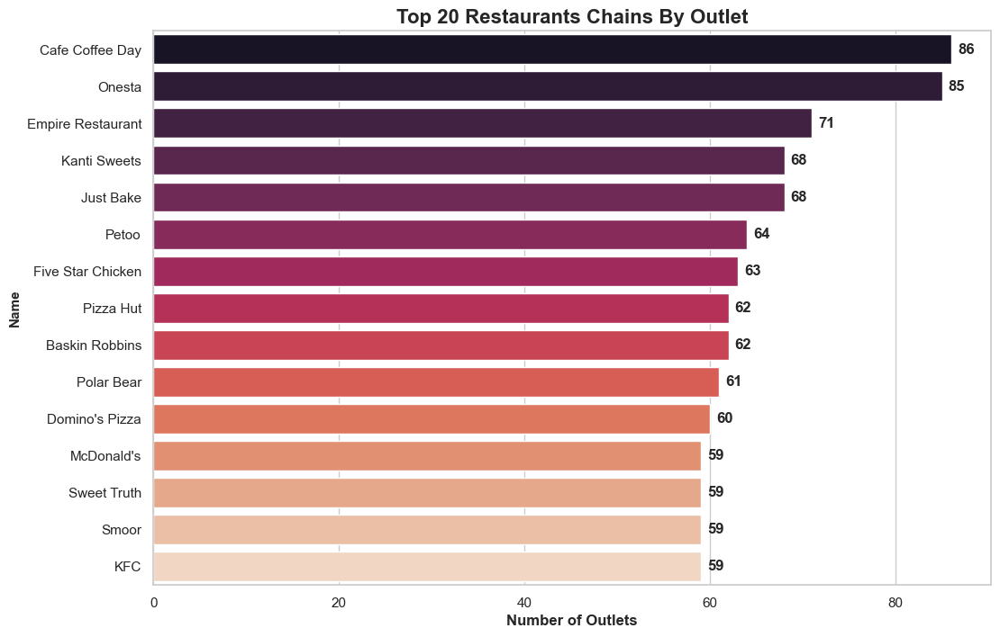

In [26]:
plt.figure(figsize=(12,8))
sns.set_theme(style="whitegrid")

ax=sns.barplot(
    x=ad.values,
    y=ad.index,
    hue=ad.index,
    palette='rocket'
)

plt.title(
    "Top 20 Restaurants Chains By Outlet",
    fontsize=16,
    weight='bold',
)
plt.xlabel("Number of Outlets", fontsize=12,weight='bold')
plt.ylabel("Name",fontsize=11,weight='bold')
for container in ax.containers:
    ax.bar_label(container,padding=5,weight='bold')

plt.show()

 1. How many restaurants are listed in the dataset?
 2. What are the most common restaurant types (e.g., casual dining, café, quick bites)?
 3. Which cuisines are most frequently offered across Bangalore?
 4. What is the distribution of restaurant ratings (average, median, skewness)?
 5. Which restaurants have the highest number of votes, and do they correlate with higher ratings?
 6. What is the average cost for two people across different localities?
 7. Is there a relationship between cost and rating (e.g., do expensive restaurants get better ratings)?
 8. Which cuisines tend to be more expensive on average?
 9. What percentage of restaurants offer online ordering?
 10. Do restaurants with online ordering have higher ratings compared to those without?
 11. Is table booking availability linked to higher customer ratings?
 12. Which locality has the maximum number of restaurants?
 13. Are certain cuisines concentrated in specific neighborhoods (e.g., South Indian in Koramangala)?
 14. Which areas have the highest density of highly-rated restaurants?

In [27]:
df['rest_type'].value_counts()

rest_type
Quick Bites                   14741
Casual Dining                  9840
Cafe                           3417
Dessert Parlor                 1902
Delivery                       1723
                              ...  
Bakery, Beverage Shop             2
Dessert Parlor, Food Court        2
Food Court, Beverage Shop         2
Quick Bites, Kiosk                1
Bakery, Food Court                1
Name: count, Length: 86, dtype: int64

There are 86 types of res_types

In [28]:
rt=df['rest_type'].value_counts().head(20)

In [29]:
rt

rest_type
Quick Bites                   14741
Casual Dining                  9840
Cafe                           3417
Dessert Parlor                 1902
Delivery                       1723
Takeaway, Delivery             1438
Casual Dining, Bar             1118
Bakery                          756
Beverage Shop                   691
Bar                             649
Food Court                      499
Bar, Casual Dining              402
Lounge                          396
Pub                             356
Sweet Shop                      348
Fine Dining                     343
Casual Dining, Cafe             309
Pub, Casual Dining              248
Beverage Shop, Quick Bites      240
Bakery, Quick Bites             231
Name: count, dtype: int64

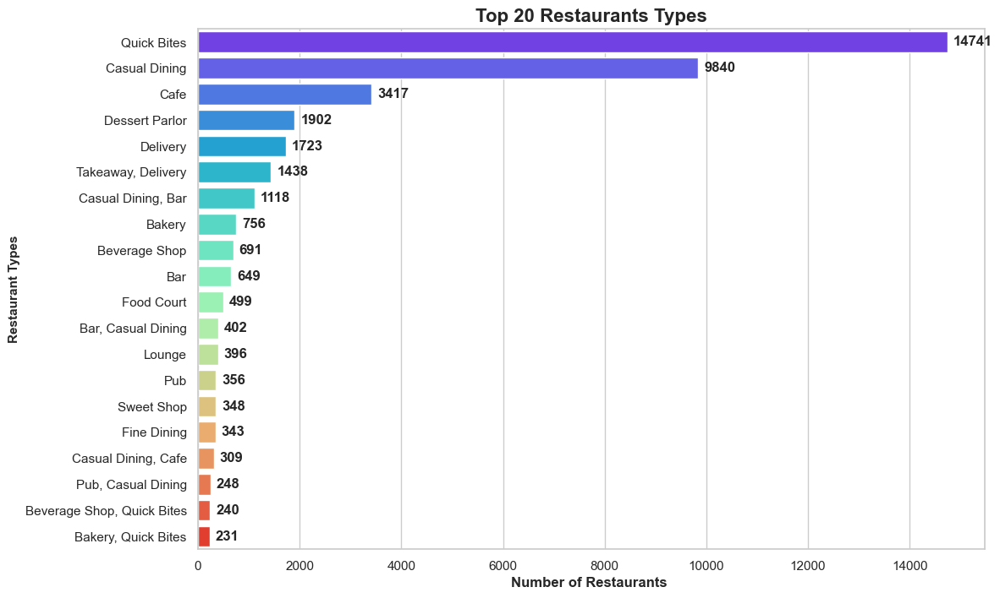

In [30]:
plt.figure(figsize=(12,8))
sns.set_theme(style="whitegrid")

rx=sns.barplot(
    x=rt.values,
    y=rt.index,
    hue=rt.index,
    palette='rainbow'
)

plt.title(
    "Top 20 Restaurants Types",
    fontsize=16,
    weight='bold',
)
plt.xlabel("Number of Restaurants ", fontsize=12,weight='bold')
plt.ylabel("Restaurant Types",fontsize=11,weight='bold')
for container in rx.containers:
    rx.bar_label(container,padding=5,weight='bold')

plt.show()

1. Quick Bites are the most found restaurant types with 14741 restaurants
2. Casual Dining have 9840 common restaurants types 

In [31]:
df['cuisines'].value_counts()

cuisines
North Indian                             2193
North Indian, Chinese                    2027
South Indian                             1250
Bakery, Desserts                          631
Cafe                                      619
                                         ... 
South Indian, Asian                         1
Chinese, Street Food, Ice Cream             1
Biryani, Kebab, Kerala                      1
North Indian, Street Food, Biryani          1
North Indian, Chinese, Arabian, Momos       1
Name: count, Length: 2479, dtype: int64

There are total 2479 Cuisines offered Accross Bangalore

In [32]:
c=df['cuisines'].value_counts().head(15)

In [33]:
c

cuisines
North Indian                           2193
North Indian, Chinese                  2027
South Indian                           1250
Bakery, Desserts                        631
Cafe                                    619
Biryani                                 618
South Indian, North Indian, Chinese     580
Fast Food                               571
Desserts                                552
Chinese                                 446
Bakery                                  430
Ice Cream, Desserts                     384
Chinese, North Indian                   345
Mithai, Street Food                     323
North Indian, Chinese, Biryani          277
Name: count, dtype: int64

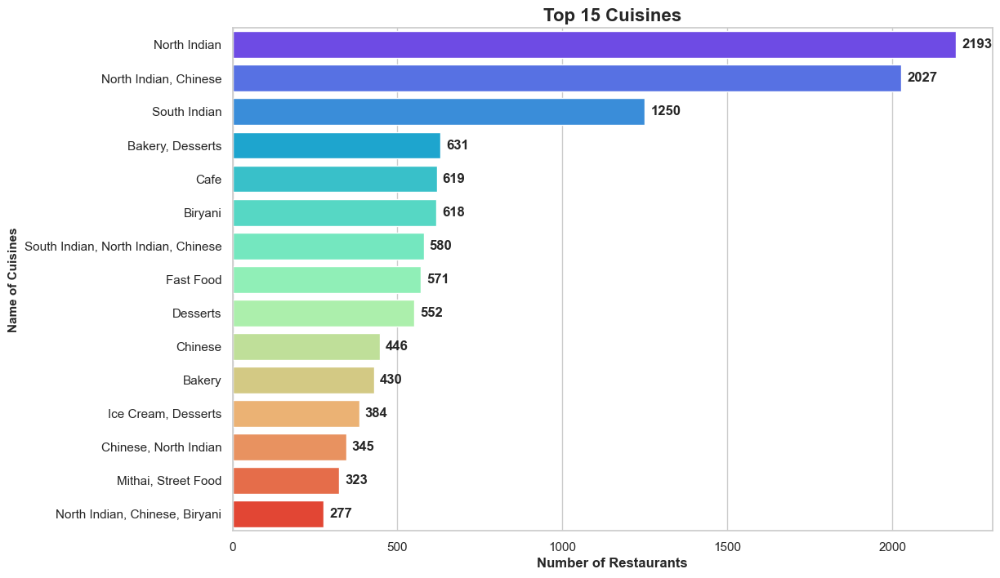

In [34]:
plt.figure(figsize=(12,8))
sns.set_theme(style="whitegrid")

cx=sns.barplot(
    x=c.values,
    y=c.index,
    hue=c.index,
    palette='rainbow'
)

plt.title(
    "Top 15 Cuisines",
    fontsize=16,
    weight='bold',
)
plt.xlabel("Number of Restaurants", fontsize=12,weight='bold')
plt.ylabel("Name of Cuisines",fontsize=11,weight='bold')
for container in cx.containers:
    cx.bar_label(container,padding=5,weight='bold')

plt.show()

In [35]:
df['location'].value_counts()

location
BTM                      4156
Koramangala 5th Block    2323
HSR                      2085
Indiranagar              1859
JP Nagar                 1823
                         ... 
West Bangalore              5
Yelahanka                   4
Rajarajeshwari Nagar        2
Nagarbhavi                  1
Peenya                      1
Name: count, Length: 92, dtype: int64

There are total 92 Locations across Bangalore 

In [36]:
l=df['location'].value_counts().head(20)

In [37]:
l

location
BTM                      4156
Koramangala 5th Block    2323
HSR                      2085
Indiranagar              1859
JP Nagar                 1823
Jayanagar                1665
Whitefield               1656
Marathahalli             1452
Bannerghatta Road        1299
Koramangala 6th Block    1075
Brigade Road             1067
Koramangala 7th Block    1047
Bellandur                1035
Koramangala 1st Block     964
Electronic City           953
Sarjapur Road             902
Ulsoor                    896
Koramangala 4th Block     844
MG Road                   808
Banashankari              799
Name: count, dtype: int64

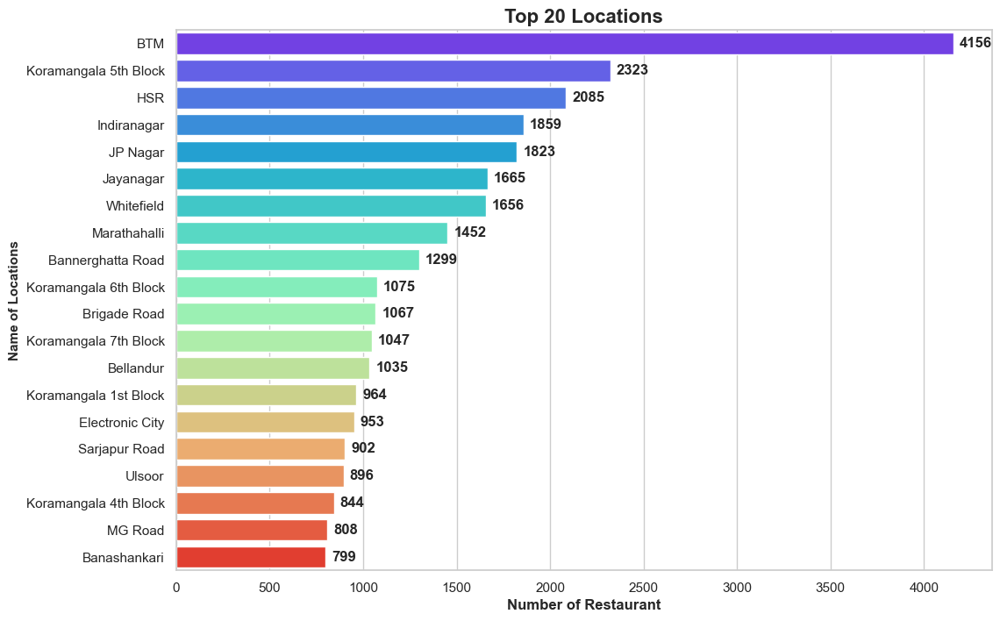

In [38]:
plt.figure(figsize=(12,8))
sns.set_theme(style="whitegrid")

lx=sns.barplot(
    x=l.values,
    y=l.index,
    hue=l.index,
    palette='rainbow'
)

plt.title(
    "Top 20 Locations",
    fontsize=16,
    weight='bold',
)
plt.xlabel("Number of Restaurant", fontsize=12,weight='bold')
plt.ylabel("Name of Locations",fontsize=11,weight='bold')
for container in lx.containers:
    lx.bar_label(container,padding=5,weight='bold')

plt.show()

In [39]:
df['dish_liked'].value_counts()

dish_liked
none                                                                                        19751
Biryani                                                                                       181
Chicken Biryani                                                                                73
Friendly Staff                                                                                 69
Waffles                                                                                        68
                                                                                            ...  
Masala Dosa, Filter Coffee, Curd Rice                                                           1
Dal Makhani, Galauti Kebab, Dum Biryani, Rasgulla, Fish, Garlic Kheer, Tandoori Broccoli        1
Fries, Peri Peri Chicken, Chicken Crisp Burger                                                  1
Burgers, Chicken Popcorn, Zinger Burger, French Fries                                           1
Rolls, Ch

In [40]:
d=df['dish_liked'].value_counts().head(15)

In [41]:
d

dish_liked
none                19751
Biryani               181
Chicken Biryani        73
Friendly Staff         69
Waffles                68
Paratha                57
Masala Dosa            56
Rooftop Ambience       42
Pizza                  38
Coffee                 34
Burgers                33
Cocktails              29
Mutton Biryani         27
Prompt Service         27
Noodles                26
Name: count, dtype: int64

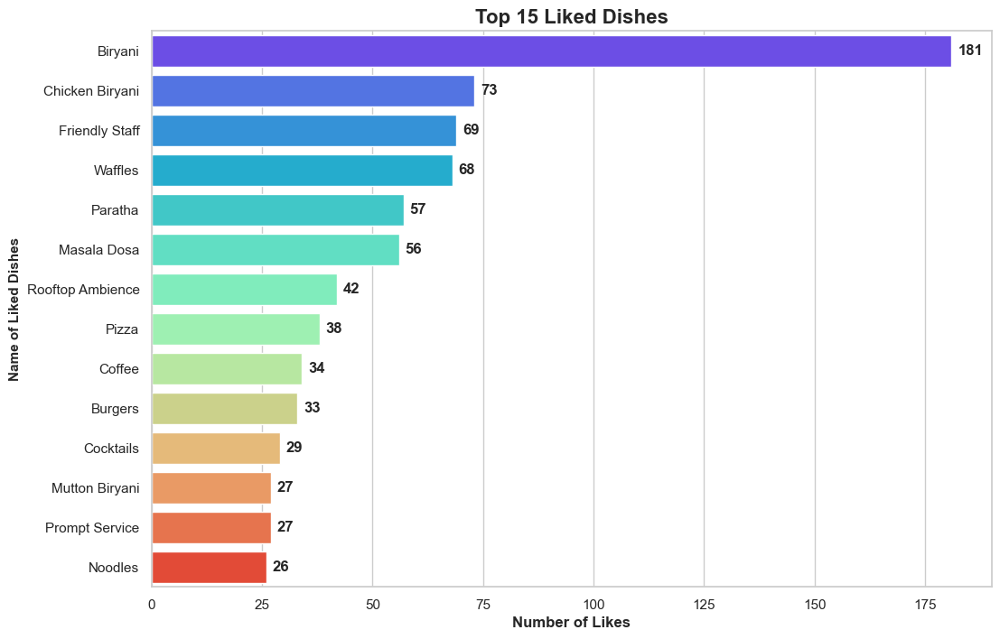

In [42]:
d_filtered = d[d.index != 'none']

plt.figure(figsize=(12,8))
sns.set_theme(style="whitegrid")

dx = sns.barplot(
    x=d_filtered.values,
    y=d_filtered.index,
    hue=d_filtered.index,
    palette='rainbow'
)

plt.title("Top 15 Liked Dishes", fontsize=16, weight='bold')
plt.xlabel("Number of Likes", fontsize=12, weight='bold')
plt.ylabel("Name of Liked Dishes", fontsize=11, weight='bold')

for container in dx.containers:
    dx.bar_label(container, padding=5, weight='bold')

plt.show()

1. We filtered 'NONE' as it has around 19751 values
2. Across Banglore Biryani has 181 Likes
3. Following with Chicken Biryani with 73 likes.

In [43]:
t=df['listed_in(type)'].value_counts()

In [44]:
t

listed_in(type)
Delivery              21416
Dine-out              14602
Desserts               2787
Cafes                  1555
Drinks & nightlife     1065
Buffet                  865
Pubs and bars           654
Name: count, dtype: int64

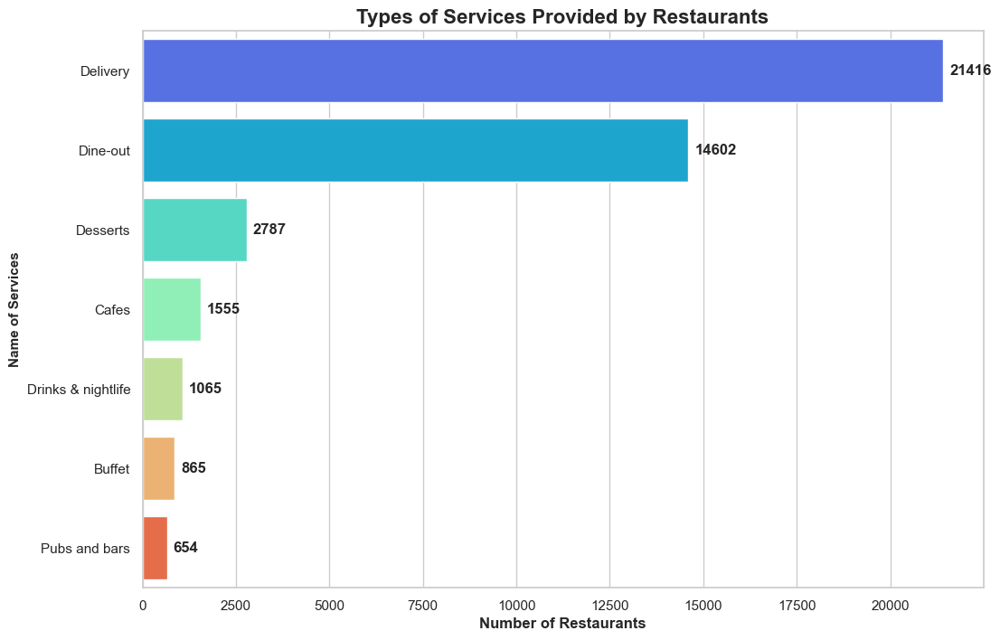

In [45]:
plt.figure(figsize=(12,8))
sns.set_theme(style="whitegrid")

tx=sns.barplot(
    x=t.values,
    y=t.index,
    hue=t.index,
    palette='rainbow'
)

plt.title(
    "Types of Services Provided by Restaurants",
    fontsize=16,
    weight='bold',
)
plt.xlabel("Number of Restaurants", fontsize=12,weight='bold')
plt.ylabel("Name of Services",fontsize=11,weight='bold')
for container in tx.containers:
    tx.bar_label(container,padding=5,weight='bold')

plt.show()

In [46]:
df['listed_in(city)'].value_counts()

listed_in(city)
BTM                      2717
Koramangala 7th Block    2433
Koramangala 5th Block    2344
Koramangala 4th Block    2323
Koramangala 6th Block    2222
Jayanagar                1965
JP Nagar                 1745
Indiranagar              1642
Church Street            1554
MG Road                  1532
Brigade Road             1515
Lavelle Road             1474
HSR                      1426
Residency Road           1355
Marathahalli             1332
Bannerghatta Road        1311
Whitefield               1234
Brookefield              1232
Old Airport Road         1208
Basavanagudi             1119
Kalyan Nagar             1060
Kammanahalli             1055
Sarjapur Road            1037
Bellandur                1013
Frazer Town               981
Malleshwaram              961
Electronic City           938
Rajajinagar               882
Banashankari              754
New BEL Road              580
Name: count, dtype: int64

In [47]:
ci=df['listed_in(city)'].value_counts().head(15)

In [48]:
ci

listed_in(city)
BTM                      2717
Koramangala 7th Block    2433
Koramangala 5th Block    2344
Koramangala 4th Block    2323
Koramangala 6th Block    2222
Jayanagar                1965
JP Nagar                 1745
Indiranagar              1642
Church Street            1554
MG Road                  1532
Brigade Road             1515
Lavelle Road             1474
HSR                      1426
Residency Road           1355
Marathahalli             1332
Name: count, dtype: int64

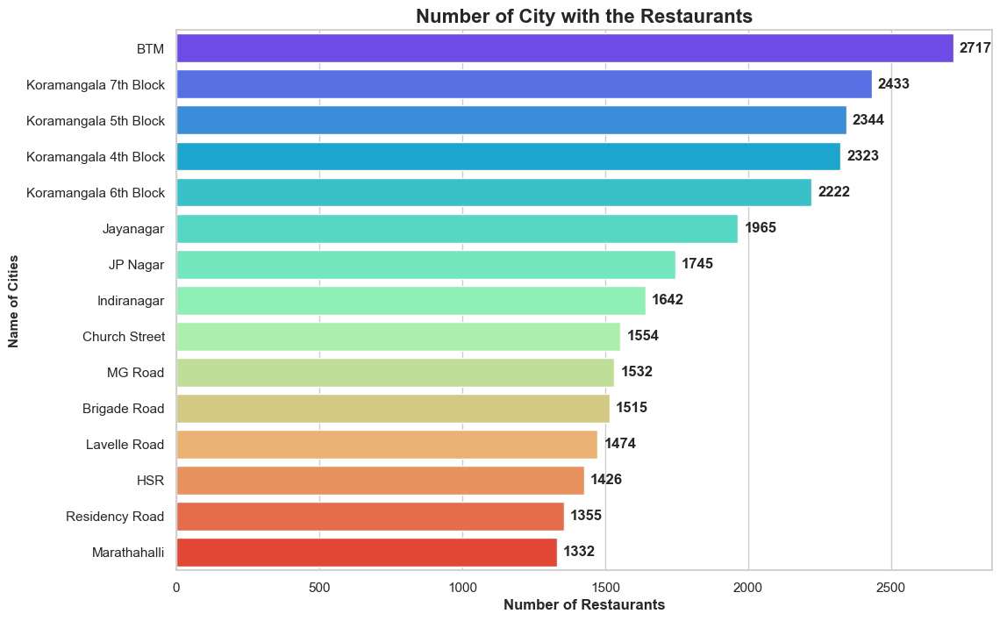

In [49]:
plt.figure(figsize=(12,8))
sns.set_theme(style="whitegrid")

cix=sns.barplot(
    x=ci.values,
    y=ci.index,
    hue=ci.index,
    palette='rainbow'
)

plt.title(
    "Number of City with the Restaurants",
    fontsize=16,
    weight='bold',
)
plt.xlabel("Number of Restaurants", fontsize=12,weight='bold')
plt.ylabel("Name of Cities",fontsize=11,weight='bold')
for container in cix.containers:
    cix.bar_label(container,padding=5,weight='bold')

plt.show()

In [50]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 42944 entries, 0 to 51716
Data columns (total 17 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   url                          42944 non-null  object 
 1   address                      42944 non-null  object 
 2   name                         42944 non-null  object 
 3   online_order                 42944 non-null  object 
 4   book_table                   42944 non-null  object 
 5   rate                         40687 non-null  float64
 6   votes                        42944 non-null  int64  
 7   phone                        42944 non-null  object 
 8   location                     42944 non-null  object 
 9   rest_type                    42944 non-null  object 
 10  dish_liked                   42944 non-null  object 
 11  cuisines                     42944 non-null  object 
 12  approx_cost(for two people)  42944 non-null  int64  
 13  reviews_list         

In [51]:
rating_data=df.loc[df['rate']>0.1,'rate']

In [52]:
fig=px.histogram(
    rating_data,
    marginal='box',
    text_auto=True,
    opacity=0.8,
    title="Distribution of Restaurant Ratings",
    labels={
        'value': "Restaurant Ratings",
        'count': "Number "
    },
    color_discrete_sequence=['#8AD6D1']
)
fig.update_traces(
    marker_line_width=0.5,
    marker_line_color='white'
)
fig.update_layout(
    title={
        'text':'Distribution of Restaurant Ratings',
        'x': 0.5,
        'font':{"size":24},
        "xanchor":"center"
    },
    xaxis=dict(title="Rating",

               title_font=dict(
                   size=18,
               )
              ),
    yaxis=dict(title="Number",

               title_font=dict(
                   size=16,
               )
              )

)
x=np.linspace(
    rating_data.min(),
    rating_data.max(),
    500
)
kde=gaussian_kde(rating_data)
density=kde(x)

bin_width=(rating_data.max()-rating_data.min())/29
kde_count=density*len(rating_data)*bin_width

fig.add_traces(
    go.Scatter(
        x=x,y=kde_count,
        mode="lines",
        name="KDE",
        line=dict(width=4)
    )
)    
fig.show()

In [53]:
df.votes

0        775
1        787
2        918
3         88
4        166
        ... 
51709     34
51711     81
51712     27
51715    236
51716     13
Name: votes, Length: 42944, dtype: int64

In [54]:
voting_data=df.loc[df['votes']>500,'votes']

In [55]:
voting_data

0         775
1         787
2         918
7        2556
9         504
         ... 
51699    1218
51700    1003
51701     673
51702    1094
51703     548
Name: votes, Length: 6654, dtype: int64

In [56]:
ac=df['approx_cost(for two people)']

In [57]:
fig=px.histogram(
    ac,
    marginal='box',
    #text_auto=True,
    opacity=0.3,
    nbins=200,
    title="Distribution of Approx Cost",
    labels={
        'value': "Restaurant Rating",
        'count': "Number "
    },
    color_discrete_sequence=['#55A9A0']
)
fig.update_traces(
    marker_line_width=0.5,
    marker_line_color="white"
)
x = np.linspace(
        ac.min(),
        ac.max(),
        500
    )
kde = gaussian_kde(ac)
density=kde(x)

bin_width=(ac.max()-ac.min())/100
kde_count =density * len(ac) *bin_width

fig.add_traces(
    go.Scatter(
        x=x,
        y=kde_count,
        mode="lines",
        name="KDE",
        line=dict(width=4)
    )
)
fig.show()

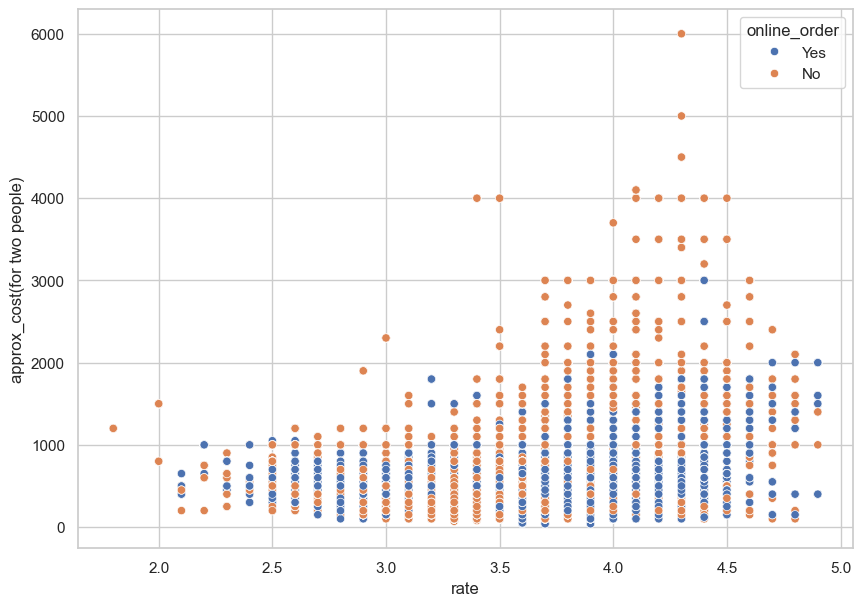

In [58]:
plt.figure(figsize=(10,7))
sns.scatterplot(
    x="rate",y='approx_cost(for two people)',hue='online_order',data=df
)
plt.show()

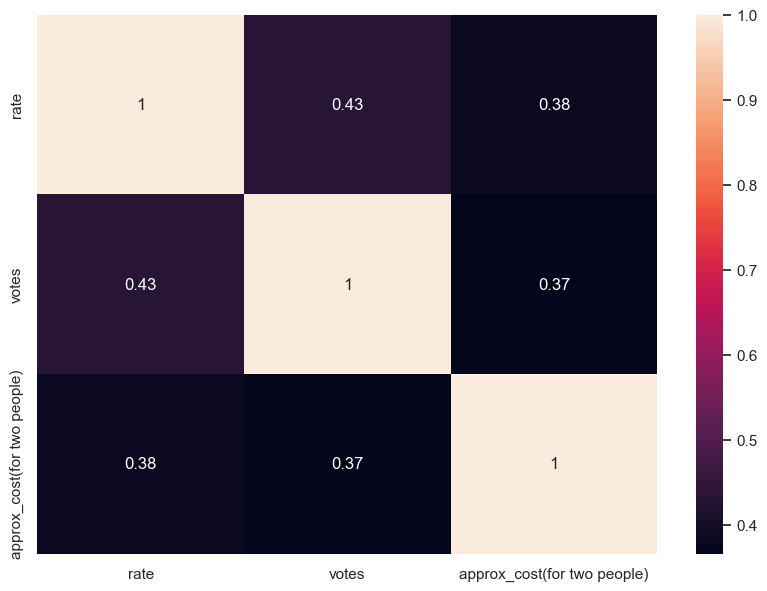

In [59]:
cor=df.corr(numeric_only=True)
plt.figure(figsize=(10,7))
sns.heatmap(cor,annot=True)
plt.show()

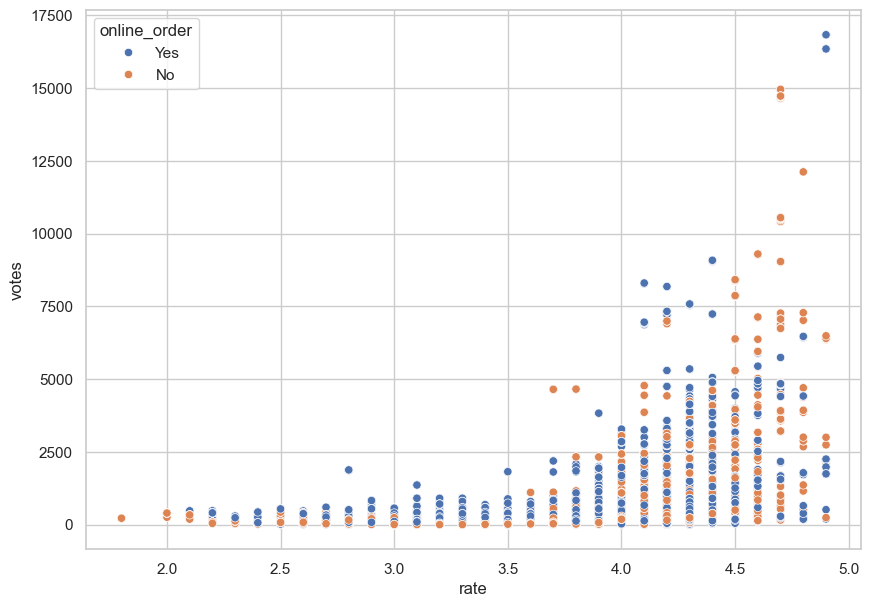

In [60]:
plt.figure(figsize=(10,7))
sns.scatterplot(
    x="rate",y='votes',hue='online_order',data=df
)
plt.show()

In [61]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 42944 entries, 0 to 51716
Data columns (total 17 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   url                          42944 non-null  object 
 1   address                      42944 non-null  object 
 2   name                         42944 non-null  object 
 3   online_order                 42944 non-null  object 
 4   book_table                   42944 non-null  object 
 5   rate                         40687 non-null  float64
 6   votes                        42944 non-null  int64  
 7   phone                        42944 non-null  object 
 8   location                     42944 non-null  object 
 9   rest_type                    42944 non-null  object 
 10  dish_liked                   42944 non-null  object 
 11  cuisines                     42944 non-null  object 
 12  approx_cost(for two people)  42944 non-null  int64  
 13  reviews_list         

In [62]:
df['listed_in(city)'].value_counts()

listed_in(city)
BTM                      2717
Koramangala 7th Block    2433
Koramangala 5th Block    2344
Koramangala 4th Block    2323
Koramangala 6th Block    2222
Jayanagar                1965
JP Nagar                 1745
Indiranagar              1642
Church Street            1554
MG Road                  1532
Brigade Road             1515
Lavelle Road             1474
HSR                      1426
Residency Road           1355
Marathahalli             1332
Bannerghatta Road        1311
Whitefield               1234
Brookefield              1232
Old Airport Road         1208
Basavanagudi             1119
Kalyan Nagar             1060
Kammanahalli             1055
Sarjapur Road            1037
Bellandur                1013
Frazer Town               981
Malleshwaram              961
Electronic City           938
Rajajinagar               882
Banashankari              754
New BEL Road              580
Name: count, dtype: int64

<Axes: ylabel='rate'>

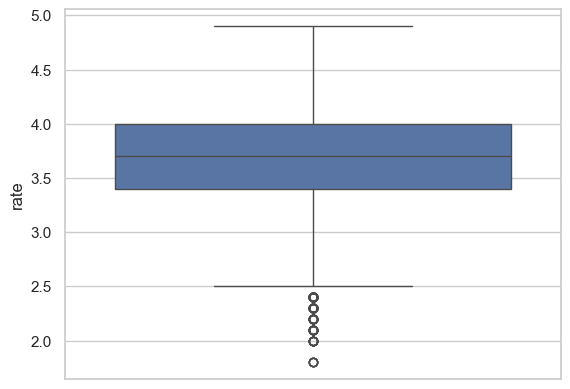

In [63]:

sns.boxplot(df['rate'])

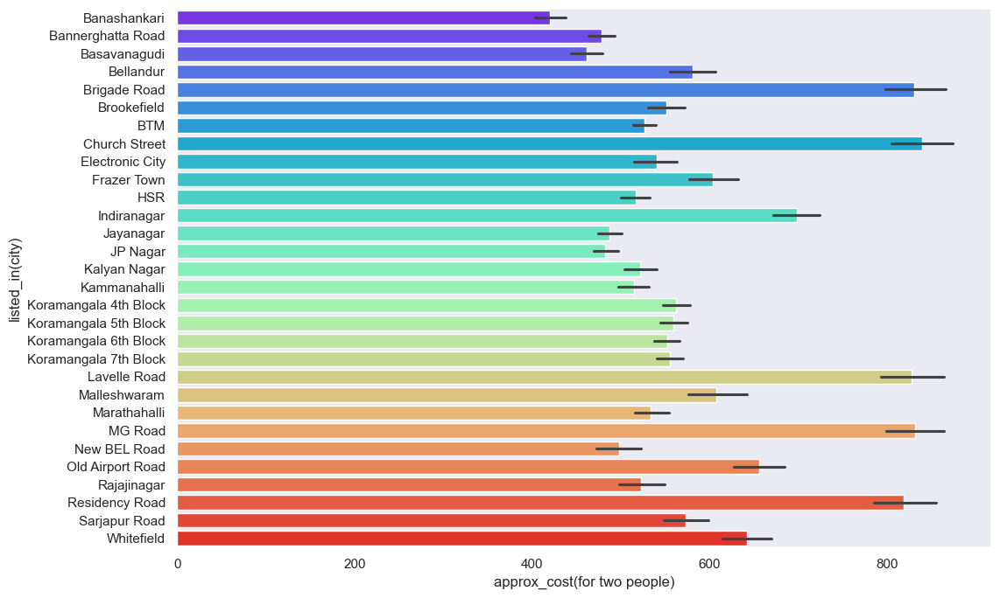

In [64]:
plt.figure(figsize=(12,8))
sns.set_theme(style="dark")

r_t=sns.barplot(
    x=df['approx_cost(for two people)'],
    y=df['listed_in(city)'],
    hue=df['listed_in(city)'],
    palette='rainbow'
)
plt.show()

In [65]:
city=df['location'].value_counts().head(20).index

In [66]:
city_df=df[df['location'].isin(city)]

In [67]:
fig=px.box(
    city_df,
    x='location',
    y='rate',
    color='book_table',
    title="Ratong Distribution by Loaction & Rate",
    labels={
        'rate':'Rating',
        'location':"Areas in Bangaluru",
        'book_table':"Table Reservation"
    }
)
fig.update_layout(
    title=dict(
        text="⭐ Rating Distribution by Online Order & Table Booking",
        font=dict(
            size=25,
            family="Arial"
        ),
        x=0.5,
        xanchor="center"
    ),
    xaxis=dict(
        title="Online Order",
        title_font=dict(size=18),
        tickfont=dict(size=14),
        showgrid=False,
        showline=True,
        linewidth=2
    ),
    yaxis=dict(
        title="Restaurant Rating",
        title_font=dict(size=18),
        tickfont=dict(size=14),
        range=[1, 5],
        dtick=0.5,
        showgrid=True,
        showline=True,
        linewidth=2
    ),
    legend=dict(
        title="Table Booking",
        font=dict(size=14)
    ),
    template="plotly_dark",
    height=650,
    width=1500,
    margin=dict(
        l=80,
        r=50,
        t=110,
        b=80
    )
)
fig.show()

In [68]:
fig=px.box(
    city_df,
    x='location',
    y='approx_cost(for two people)',
    color='online_order'
)
fig.show()

In [69]:
pip install pandas plotly geopy

In [70]:
import folium
import time
import os
from geopy.geocoders import Nominatim
from geopy.extra.rate_limiter import RateLimiter
from folium.plugins import HeatMap, Fullscreen

In [71]:
pip install folium

Note: you may need to restart the kernel to use updated packages.


In [72]:
locations=pd.DataFrame({"Name":df['location'].unique()})

locations['Name']=locations['Name'].apply(lambda x:f" {str(x).strip()}, Bangalore, India")

In [73]:
locations

,Name
0,"Banashankari, Bangalore, India"
1,"Basavanagudi, Bangalore, India"
2,"Mysore Road, Bangalore, India"
3,"Jayanagar, Bangalore, India"
4,"Kumaraswamy Layout, Bangalore, India"
...,...
87,"Sahakara Nagar, Bangalore, India"
88,"Jalahalli, Bangalore, India"
89,"Nagarbhavi, Bangalore, India"
90,"Peenya, Bangalore, India"


In [74]:
geolocator=Nominatim(user_agent="zomato_app")
geocode= RateLimiter(
geolocator.geocode,
min_delay_seconds=1.1,
max_retries=2,
error_wait_seconds=2.0
)

In [75]:
lat_lon=[]
geolocator=Nominatim (user_agent="zomato_app_v1_soham") # give Unique Name
for location in locations['Name']:
    try:
        location = geocode(location)
        if location is None:
            lat_lon.append(np.nan)
        else:
            lat_lon.append((location.latitude, location.longitude))
    except Exception as e:
        print(f"Error for (location_name):{e}")
        lat_lon.append(np.nan)

In [76]:
locations["geo_code"]=lat_lon

In [77]:
locations

,Name,geo_code
0,"Banashankari, Bangalore, India","(12.9278196, 77.556621)"
1,"Basavanagudi, Bangalore, India","(12.9417261, 77.5755021)"
2,"Mysore Road, Bangalore, India","(12.9466619, 77.5300896)"
3,"Jayanagar, Bangalore, India","(12.9292731, 77.5824229)"
4,"Kumaraswamy Layout, Bangalore, India","(12.9150398, 77.5678879)"
...,...,...
87,"Sahakara Nagar, Bangalore, India","(13.0621474, 77.5800614)"
88,"Jalahalli, Bangalore, India","(13.0394104, 77.5197351)"
89,"Nagarbhavi, Bangalore, India","(12.9512353, 77.519054)"
90,"Peenya, Bangalore, India","(13.0329814, 77.5331801)"


In [78]:
locations [["Latitude", "Longitude"]] = pd.DataFrame(
    locations ["geo_code"].apply(
        lambda x: x if isinstance(x, tuple) else (np. nan, np.nan)
    ).tolist(),
    index=locations.index
)

In [79]:
locations

,Name,geo_code,Latitude,Longitude
0,"Banashankari, Bangalore, India","(12.9278196, 77.556621)",12.927820,77.556621
1,"Basavanagudi, Bangalore, India","(12.9417261, 77.5755021)",12.941726,77.575502
2,"Mysore Road, Bangalore, India","(12.9466619, 77.5300896)",12.946662,77.530090
3,"Jayanagar, Bangalore, India","(12.9292731, 77.5824229)",12.929273,77.582423
4,"Kumaraswamy Layout, Bangalore, India","(12.9150398, 77.5678879)",12.915040,77.567888
...,...,...,...,...
87,"Sahakara Nagar, Bangalore, India","(13.0621474, 77.5800614)",13.062147,77.580061
88,"Jalahalli, Bangalore, India","(13.0394104, 77.5197351)",13.039410,77.519735
89,"Nagarbhavi, Bangalore, India","(12.9512353, 77.519054)",12.951235,77.519054
90,"Peenya, Bangalore, India","(13.0329814, 77.5331801)",13.032981,77.533180


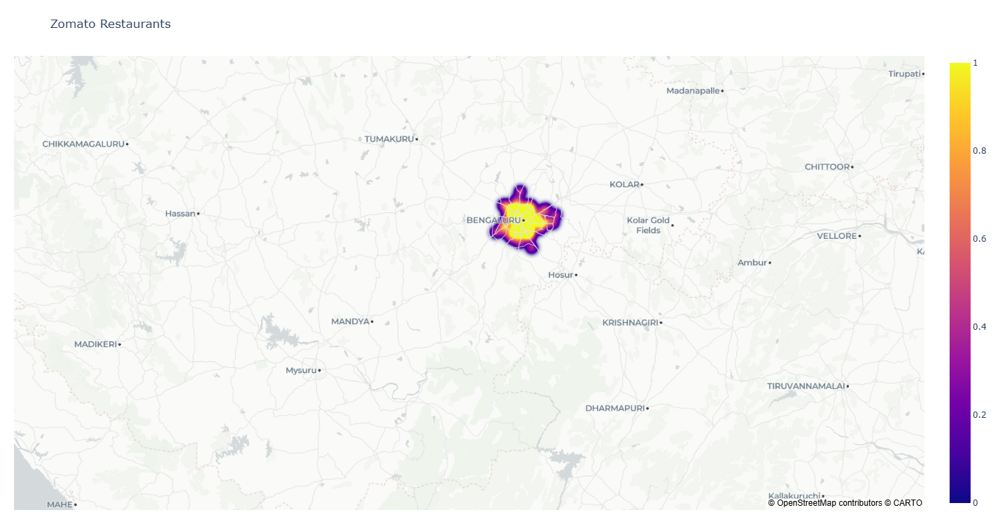

In [80]:
fig=px.density_map(
    locations,
    lat="Latitude",
    lon="Longitude",
    radius=15,
    zoom=8.5,
    map_style='carto-positron',
    title="Zomato Restaurants"
)
fig.update_layout(
    height=750,
    margin=dict(l=20,r=20,t=80,b=20)
)
fig.show()

## Conclusion

The Zomato Restaurant Analytics project provides valuable insights into Bangalore's restaurant industry by analyzing restaurant ratings, customer preferences, pricing, online ordering services, restaurant types, and geographical distribution. The analysis began with a dataset containing 51,717 records and 17 columns, followed by data cleaning, preprocessing, and exploratory data analysis using Python libraries such as Pandas, NumPy, Matplotlib, Seaborn, and Plotly.

The key findings indicate that **Quick Bites and Casual Dining are the most common restaurant types**, with 14,741 and 9,840 records, respectively. The dataset covers 2,479 cuisine combinations across 92 locations in Bangalore, highlighting the diversity of the city's food industry. The average restaurant rating is approximately 3.5 out of 5, while the average cost for two people is approximately ₹596.75, indicating a wide range of dining options for different budgets.

Online ordering is an important part of Bangalore's restaurant ecosystem, with 27,985 restaurants accepting online orders compared with 14,959 that do not. This suggests substantial adoption of online ordering among the restaurants represented in the dataset. The analysis also explored customer ratings, votes, restaurant costs, table-booking availability, and location-based patterns to understand the factors influencing restaurant performance and customer engagement. Additionally, the cuisine analysis identified Biryani and Chicken Biryani among the frequently liked dishes recorded in the dataset.

Overall, this project demonstrates how data analytics can transform raw restaurant data into meaningful business insights. These insights can help restaurant owners understand customer preferences, evaluate pricing strategies, assess online ordering opportunities, and identify promising locations. The project also demonstrates the practical application of Python for data cleaning, exploratory data analysis, statistical exploration, and interactive visualization to support data-driven decision-making in the food and hospitality industry.